# Domácí úkol č. 1 - 🕵️‍♀️ Explorační analýza dat

## 📚 Data
V souborech `intakes.csv` a `outcomes.csv` naleznete data z útulku ve městě Austin, Texas USA. Data pocházejí z oficiálního [zdroje otevřených dat města Austin](https://data.austintexas.gov/).

Dataset [intakes](https://data.austintexas.gov/Health-and-Community-Services/Austin-Animal-Center-Intakes/wter-evkm) obsahuje data o přijatých zvířatech od 1. 10. 2013 do 6. 10. 2024. Dataset [outcomes](https://data.austintexas.gov/Health-and-Community-Services/Austin-Animal-Center-Outcomes/9t4d-g238) obsahuje údaje o zvířatech, která útulek opustila (např. byla adoptována, vrácena majiteli a podobně) za tentýž časový interval. Může se stát, že zvířata přijatá do 1. 10. 2013 se nevyskytují v `intakes.csv` (data se ještě neshromažďovala), ale budou mít záznam v `outcomes.csv`, pokud útulek po tomto datu opustila.

☝️ Každý dataset může **stejné zvíře obsahovat víckrát** (1. některá zvířata se do útulku vracela - to je trochu komplikace, pokud byste datasety chtěli spojit - pro řešení úkolu spojování ale není nutné, 2. některé záznamy jsou duplicitní - ty můžete odstranit, jedná se o chybu). 

## Zadání
> ☝️ Používejte markdown buňky! Zdůvodňujte všechny důležité kroky, popisujte vizualizace a co je z nich možné pozorovat. Za nepřehledný domácí úkol nebudou uděleny body.

> ❌ Zkopírovaný kód ze cvičení (především ze cvičení 2) nebude uznán!

> ‼️ Akceptovatelný je úkol pouze v češtině, slovenštině nebo angličtině.

Za řádné průběžné komentování a vizuální prezentaci postupu a výsledků lze získat až 3 body.

**✨ Příprava dat** (celkem 4 body)
* Importujte potřebné balíčky.
* Načtěte si datasety intakes a outcomes z příslušných csv souborů.
* Seznamte se s oběma datasety a svá zjištění komentujte:
  * Příklad informací, které lze zjistit: počet řádků datasetu, počet a význam příznaků, datový typ příznaků a počet jejich unikátních hodnot, ...
* Vyčistěte a zkonvertujte data:
  * Zjistěte jakým způsobem jsou v datasetu uváděny chybějící hodnoty a v případě potřeby je přepište na NaN.
  * Zkonvertujte kategorické příznaky na typ category.
  * Převeďte příznak Age upon Intake/Outcome na numerický příznak.
  * Převeďte příznak DateTime na typ datetime64.
  * Proveďte všechny další úpravy, které vám dávají smysl (konverze dalších příznaků, odstranění duplicitních údajů, přidání nových příznaků, ...).
  
**🖊️ Deskriptivní statistiky** (celkem 6 bodů)

Volbu vhodných statistik pro daný typ dat komentujte a pokud je to možné, využívejte co nejvíce vizualizace.
* Popište příznaky Age upon Intake a DateTime (původně z datasetu intakes) pomocí univariačních deskriptivních statistik.
* Vyberte si tři další příznaky a popište je pomocí univariačních deskriptivních statistik, které jsou pro ně vhodné.
* Vyberte si dva příznaky, mezi kterými by mohl být nějaký vztah (např. korelace) a popište tento vztah pomocí bivariačních deskriptivních statistik. Dvojice typu Age upon Intake a Age upon Outcome neuznáváme.

**❓ Zadané otázky** (2 body za každou otázku, celkem max. 6 bodů)

Pomocí vhodných vizualizací odpovídejte na následující otázky:
* Závisí typ odchodu zvířete z útulku (Outcome Type) na typu příchodu (Intake Type)? Pokud chcete, uvažujte pro zjednodušení pouze zvířata, která se v každém datasetu vyskytují právě jednou.
* Hraje věk zvířete roli při adopci?
* Je příjem zvířat v rámci roku konstantní nebo existují období s větší/nižší zátěží?

K jedné otázce můžete v případě potřeby vytvořit více vizualizací. Výsledek vizualizace a všechny mezikroky komentujte.

**❓ Vlastní otázky** (2 body za každou otázku, celkem max. 6 bodů)

Vymyslete **minimálně tři** vlastní otázky a odpovídejte na ně vhodnými vizualizacemi. Otázky můžete postavit na již zmíněných datasetech. Také je možné využít třetí dataset [locations](https://data.austintexas.gov/Health-and-Community-Services/Austin-Animal-Center-Found-Pets-Map/hye6-gvq2), který naleznete v souboru locations.csv, nebo si můžete stáhnout nějaká další zajímavá data, která souvisí s tímto tématem.

Dataset locations poskytuje informace o všech toulavých kočkách a psech, které jsou v databázi útulku **méně než týden**. Většina se nachází v útulku, ale část z nich je u dobrovolníků – tato informace je uvedena ve sloupci At AAC (AAC – Austin Animal Center).

### Bodové hodnocení
Shrnutí bodů, které můžete nejvýše získat:
- 3 body za komentáře a vizuální prezentaci postupu a výsledků,
- 4 body za přípravu dat,
- 6 bodů za deskriptivní statistiku,
- 6 bodů za zodpovězení všech zadaných otázek,
- 6 bodů za definici a zodpovězení minimálně tří vlastních otázek.

Celkem lze za domácí úkol č. 1 získat maximálně 25 bodů.

# **1. Data Prepearing**

**Here is we importing libraries that we need:**

In [1]:
import matplotlib.pyplot as plt
import squarify
import seaborn as sns

import pandas as pd
import numpy as np

In [2]:
sns.set_style("darkgrid")
sns.set_palette(sns.color_palette("Set3", 10))

Now we have to read data from a files intakes.csv and outakes.csv:

In [3]:
intakes_df = pd.read_csv('intakes.csv')
outcomes_df = pd.read_csv('outcomes.csv')

✅ Data was successfully read and now using command **info()** we can see general information about data in these files: 

In [4]:
intakes_df.info()
outcomes_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 167556 entries, 0 to 167555
Data columns (total 12 columns):
 #   Column            Non-Null Count   Dtype 
---  ------            --------------   ----- 
 0   Animal ID         167556 non-null  object
 1   Name              119338 non-null  object
 2   DateTime          167556 non-null  object
 3   MonthYear         167556 non-null  object
 4   Found Location    167556 non-null  object
 5   Intake Type       167556 non-null  object
 6   Intake Condition  167556 non-null  object
 7   Animal Type       167556 non-null  object
 8   Sex upon Intake   167554 non-null  object
 9   Age upon Intake   167555 non-null  object
 10  Breed             167556 non-null  object
 11  Color             167556 non-null  object
dtypes: object(12)
memory usage: 15.3+ MB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 167559 entries, 0 to 167558
Data columns (total 12 columns):
 #   Column            Non-Null Count   Dtype 
---  ------            --------

Using command **shape** to show an info about count of rows and columns in dataset;\
Using command **display()** we will see the first and the last 5 rows of data in our datasets:

In [5]:
print(f'\nNumber of rows and columns in intakes dataset: {intakes_df.shape}')
print(f'\nNumber of rows and columns in outcomes dataset: {outcomes_df.shape}')

display(intakes_df)
display(outcomes_df)


Number of rows and columns in intakes dataset: (167556, 12)

Number of rows and columns in outcomes dataset: (167559, 12)


,Animal ID,Name,DateTime,MonthYear,Found Location,Intake Type,Intake Condition,Animal Type,Sex upon Intake,Age upon Intake,Breed,Color
0,A786884,*Brock,01/03/2019 04:19:00 PM,January 2019,2501 Magin Meadow Dr in Austin (TX),Stray,Normal,Dog,Neutered Male,2 years,Beagle Mix,Tricolor
1,A706918,Belle,07/05/2015 12:59:00 PM,July 2015,9409 Bluegrass Dr in Austin (TX),Stray,Normal,Dog,Spayed Female,8 years,English Springer Spaniel,White/Liver
2,A724273,Runster,04/14/2016 06:43:00 PM,April 2016,2818 Palomino Trail in Austin (TX),Stray,Normal,Dog,Intact Male,11 months,Basenji Mix,Sable/White
3,A665644,NaN,10/21/2013 07:59:00 AM,October 2013,Austin (TX),Stray,Sick,Cat,Intact Female,4 weeks,Domestic Shorthair Mix,Calico
4,A857105,Johnny Ringo,05/12/2022 12:23:00 AM,May 2022,4404 Sarasota Drive in Austin (TX),Public Assist,Normal,Cat,Neutered Male,2 years,Domestic Shorthair,Orange Tabby
...,...,...,...,...,...,...,...,...,...,...,...,...
167551,A914747,NaN,10/06/2024 12:31:00 PM,October 2024,14312 Hunters Bend in Austin (TX),Stray,Normal,Dog,Intact Female,2 years,Pit Bull,White/Gray
167552,A895580,*Dean,10/06/2024 11:29:00 AM,October 2024,Austin (TX),Owner Surrender,Normal,Dog,Neutered Male,3 years,Pit Bull,Brown Brindle/White
167553,A914678,Jade,10/04/2024 06:12:00 PM,October 2024,East 6Th Street in Austin (TX),Stray,Injured,Cat,Unknown,2 years,Domestic Longhair,Black/White
167554,A914450,*Dasher,10/01/2024 08:45:00 AM,October 2024,7201 Levander Loop in Austin (TX),Stray,Normal,Dog,Intact Male,5 years,Dachshund Wirehair Mix,Brown/Tan


,Animal ID,Name,DateTime,MonthYear,Date of Birth,Outcome Type,Outcome Subtype,Animal Type,Sex upon Outcome,Age upon Outcome,Breed,Color
0,A882831,*Hamilton,07/01/2023 06:12:00 PM,Jul 2023,03/25/2023,Adoption,NaN,Cat,Neutered Male,3 months,Domestic Shorthair Mix,Black/White
1,A794011,Chunk,05/08/2019 06:20:00 PM,May 2019,05/02/2017,Rto-Adopt,NaN,Cat,Neutered Male,2 years,Domestic Shorthair Mix,Brown Tabby/White
2,A776359,Gizmo,07/18/2018 04:02:00 PM,Jul 2018,07/12/2017,Adoption,NaN,Dog,Neutered Male,1 year,Chihuahua Shorthair Mix,White/Brown
3,A821648,NaN,08/16/2020 11:38:00 AM,Aug 2020,08/16/2019,Euthanasia,NaN,Other,Unknown,1 year,Raccoon,Gray
4,A720371,Moose,02/13/2016 05:59:00 PM,Feb 2016,10/08/2015,Adoption,NaN,Dog,Neutered Male,4 months,Anatol Shepherd/Labrador Retriever,Buff
...,...,...,...,...,...,...,...,...,...,...,...,...
167554,A914585,NaN,10/06/2024 04:21:00 PM,Oct 2024,10/03/2022,Euthanasia,Rabies Risk,Other,Unknown,2 years,Raccoon,Gray/White
167555,A914548,NaN,10/03/2024 01:18:00 PM,Oct 2024,10/02/2022,Transfer,Partner,Dog,Intact Female,2 years,Labrador Retriever,Cream
167556,A914369,NaN,10/06/2024 11:23:00 AM,Oct 2024,09/30/2022,Disposal,NaN,Cat,Intact Female,2 years,Domestic Shorthair,Gray/White
167557,A722952,Guero,10/06/2024 11:51:00 AM,Oct 2024,03/24/2014,Rto-Adopt,NaN,Dog,Neutered Male,10 years,American Pit Bull Terrier Mix,Tan/White


Using command **nunique()** look at the type of data in each column and see how many unique values each column has.

In [6]:
intakes_df.nunique()

Animal ID           150561
Name                 29042
DateTime            115549
MonthYear              133
Found Location       67994
Intake Type              6
Intake Condition        20
Animal Type              5
Sex upon Intake          5
Age upon Intake         55
Breed                 2966
Color                  650
dtype: int64

In [7]:
outcomes_df.nunique()

Animal ID           150558
Name                 28979
DateTime            139792
MonthYear              133
Date of Birth         8486
Outcome Type            11
Outcome Subtype         26
Animal Type              5
Sex upon Outcome         5
Age upon Outcome        55
Breed                 2964
Color                  653
dtype: int64

🔀 We are replacing missing or ambiguous values such as **empty strings, Unknown, and None** with **NaN** in both the intakes_df and outcomes_df datasets.

In [8]:
intakes_df.replace(['', 'Unknown', 'None'], np.nan, inplace=True)
outcomes_df.replace(['', 'Unknown', 'None'], np.nan, inplace=True)

✏️ We wrote a function **age_to_days()** for converting age values from a string format to the total number of days.

Using this function we converted **Age upon Intake** and **Age upon Outcome** to float64 format. If a date had negative we changed it to NaN.

In [9]:
def age_to_days(age):
    if pd.isnull(age) or not isinstance(age, str):
        return np.nan
    parts = age.split()
    if len(parts) != 2:
        return np.nan
    value, unit = parts
    try:
        value = float(value)
        if value < 0:
            return np.nan
    except ValueError:
        return np.nan

    if 'year' in unit:
        return value
    elif 'month' in unit:
        return value/12
    elif 'week' in unit:
        return value/52
    elif 'day' in unit:
        return value/365
    else:
        return np.nan


intakes_df['Age upon Intake'] = intakes_df['Age upon Intake'].apply(age_to_days)
outcomes_df['Age upon Outcome'] = outcomes_df['Age upon Outcome'].apply(age_to_days)

intakes_df['Age upon Intake'] = intakes_df['Age upon Intake'].astype('float64')
outcomes_df['Age upon Outcome'] = outcomes_df['Age upon Outcome'].astype('float64')

🔁1. We are converting categorical columns to **category** datatype

🔁2. We are converting **DateTime** column to a **dateTime** format

✅3. We are removing **duplicates** from datasets

In [10]:
intakesToCategory = ['Animal ID','Name','MonthYear', 'Found Location', 'Intake Type', 'Intake Condition', 'Animal Type', 'Sex upon Intake', 'Breed', 'Color']
outcomesToCategory = ['Animal ID', 'Name', 'MonthYear', 'Date of Birth', 'Outcome Type', 'Outcome Subtype', 'Animal Type', 'Sex upon Outcome', 'Breed', 'Color']

intakes_df[intakesToCategory] = intakes_df[intakesToCategory].astype('category')
outcomes_df[outcomesToCategory] = outcomes_df[outcomesToCategory].astype('category')

intakes_df['DateTime'] = pd.to_datetime(intakes_df['DateTime'], format='%m/%d/%Y %I:%M:%S %p')
outcomes_df['DateTime'] = pd.to_datetime(outcomes_df['DateTime'], format='%m/%d/%Y %I:%M:%S %p')
outcomes_df['Date of Birth'] = pd.to_datetime(outcomes_df['Date of Birth'], format='%m/%d/%Y')


intakes_df.drop_duplicates(inplace=True)
outcomes_df.drop_duplicates(inplace=True)


🚀 Now we're ready

In [11]:
display(intakes_df)
display(outcomes_df)

,Animal ID,Name,DateTime,MonthYear,Found Location,Intake Type,Intake Condition,Animal Type,Sex upon Intake,Age upon Intake,Breed,Color
0,A786884,*Brock,2019-01-03 16:19:00,January 2019,2501 Magin Meadow Dr in Austin (TX),Stray,Normal,Dog,Neutered Male,2.000000,Beagle Mix,Tricolor
1,A706918,Belle,2015-07-05 12:59:00,July 2015,9409 Bluegrass Dr in Austin (TX),Stray,Normal,Dog,Spayed Female,8.000000,English Springer Spaniel,White/Liver
2,A724273,Runster,2016-04-14 18:43:00,April 2016,2818 Palomino Trail in Austin (TX),Stray,Normal,Dog,Intact Male,0.916667,Basenji Mix,Sable/White
3,A665644,NaN,2013-10-21 07:59:00,October 2013,Austin (TX),Stray,Sick,Cat,Intact Female,0.076923,Domestic Shorthair Mix,Calico
4,A857105,Johnny Ringo,2022-05-12 00:23:00,May 2022,4404 Sarasota Drive in Austin (TX),Public Assist,Normal,Cat,Neutered Male,2.000000,Domestic Shorthair,Orange Tabby
...,...,...,...,...,...,...,...,...,...,...,...,...
167551,A914747,NaN,2024-10-06 12:31:00,October 2024,14312 Hunters Bend in Austin (TX),Stray,Normal,Dog,Intact Female,2.000000,Pit Bull,White/Gray
167552,A895580,*Dean,2024-10-06 11:29:00,October 2024,Austin (TX),Owner Surrender,Normal,Dog,Neutered Male,3.000000,Pit Bull,Brown Brindle/White
167553,A914678,Jade,2024-10-04 18:12:00,October 2024,East 6Th Street in Austin (TX),Stray,Injured,Cat,NaN,2.000000,Domestic Longhair,Black/White
167554,A914450,*Dasher,2024-10-01 08:45:00,October 2024,7201 Levander Loop in Austin (TX),Stray,Normal,Dog,Intact Male,5.000000,Dachshund Wirehair Mix,Brown/Tan


,Animal ID,Name,DateTime,MonthYear,Date of Birth,Outcome Type,Outcome Subtype,Animal Type,Sex upon Outcome,Age upon Outcome,Breed,Color
0,A882831,*Hamilton,2023-07-01 18:12:00,Jul 2023,2023-03-25,Adoption,NaN,Cat,Neutered Male,0.250000,Domestic Shorthair Mix,Black/White
1,A794011,Chunk,2019-05-08 18:20:00,May 2019,2017-05-02,Rto-Adopt,NaN,Cat,Neutered Male,2.000000,Domestic Shorthair Mix,Brown Tabby/White
2,A776359,Gizmo,2018-07-18 16:02:00,Jul 2018,2017-07-12,Adoption,NaN,Dog,Neutered Male,1.000000,Chihuahua Shorthair Mix,White/Brown
3,A821648,NaN,2020-08-16 11:38:00,Aug 2020,2019-08-16,Euthanasia,NaN,Other,NaN,1.000000,Raccoon,Gray
4,A720371,Moose,2016-02-13 17:59:00,Feb 2016,2015-10-08,Adoption,NaN,Dog,Neutered Male,0.333333,Anatol Shepherd/Labrador Retriever,Buff
...,...,...,...,...,...,...,...,...,...,...,...,...
167554,A914585,NaN,2024-10-06 16:21:00,Oct 2024,2022-10-03,Euthanasia,Rabies Risk,Other,NaN,2.000000,Raccoon,Gray/White
167555,A914548,NaN,2024-10-03 13:18:00,Oct 2024,2022-10-02,Transfer,Partner,Dog,Intact Female,2.000000,Labrador Retriever,Cream
167556,A914369,NaN,2024-10-06 11:23:00,Oct 2024,2022-09-30,Disposal,NaN,Cat,Intact Female,2.000000,Domestic Shorthair,Gray/White
167557,A722952,Guero,2024-10-06 11:51:00,Oct 2024,2014-03-24,Rto-Adopt,NaN,Dog,Neutered Male,10.000000,American Pit Bull Terrier Mix,Tan/White


# **2. Descriptive statistics :)**

## 1. Age Upon Intake

General description for **Age upon Intake**:

In [12]:
print('Descriptive statistics for Age upon Intake:')
intakes_df['Age upon Intake'].describe().apply(lambda x: f"{x:.2f}")

Descriptive statistics for Age upon Intake:


count    167514.00
mean          1.95
std           2.80
min           0.00
25%           0.17
50%           1.00
75%           2.00
max          30.00
Name: Age upon Intake, dtype: object

🖌️ Let's draw a graf to check dependencies between Age of animal and getting it to a shelter.

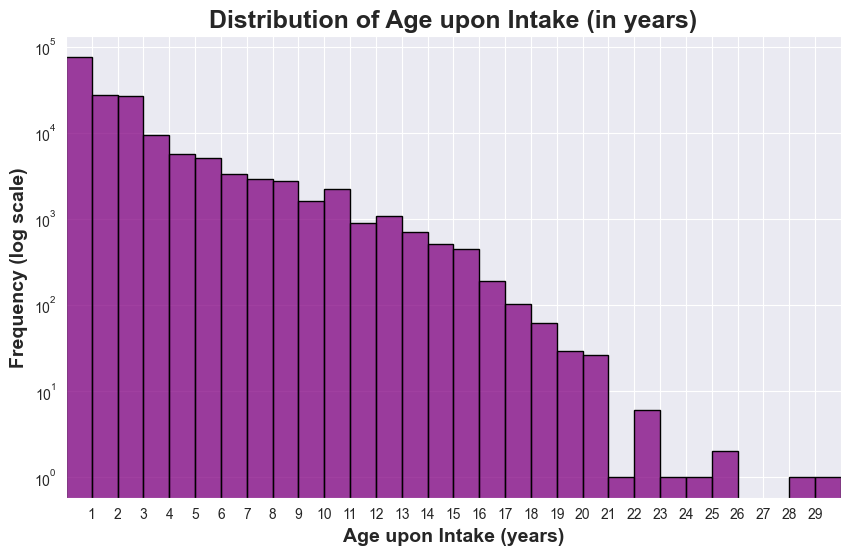

In [13]:
plt.figure(figsize=(10, 6))
sns.histplot(intakes_df['Age upon Intake'], bins=30, edgecolor='black', color='purple')
plt.title('Distribution of Age upon Intake (in years)', fontweight='bold', fontsize=18)
plt.xlabel('Age upon Intake (years)', fontweight='bold', fontsize=14)
plt.ylabel('Frequency (log scale)', fontweight='bold', fontsize=14)
plt.xlim([0, 30])
plt.xticks(ticks=range(1, 30, 1))
plt.yscale('log')
plt.grid(True)
plt.show()

We can see that most of the animals entering the shelter are young. As age increases, the intake frequency significantly decreases, especially for animals older than 10 years. Animals older than 20 years are extremely rare.

## 2. DateTime

### Distribution by Year

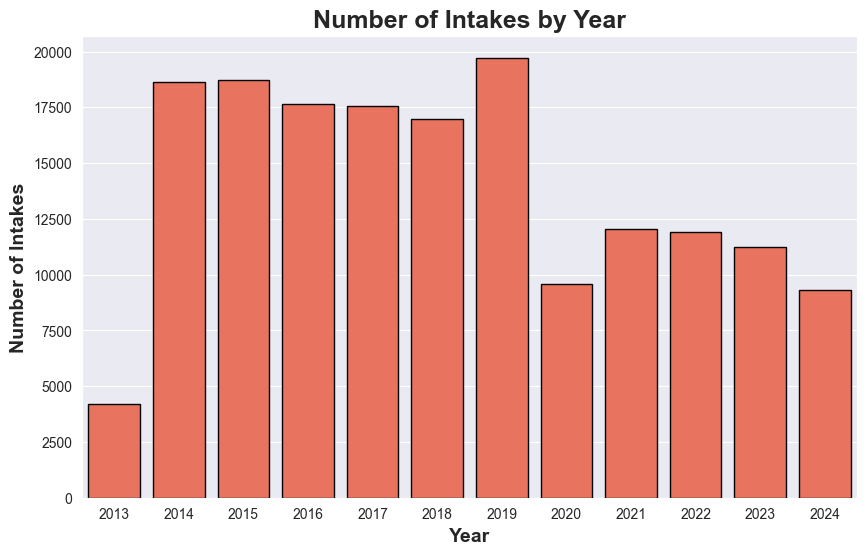

In [14]:
intakes_df['Intake Year'] = intakes_df['DateTime'].dt.year

plt.figure(figsize=(10, 6))
year_counts = intakes_df['Intake Year'].value_counts().sort_index()

sns.barplot(x=year_counts.index, y=year_counts.values, color='tomato', edgecolor='black')
plt.title('Number of Intakes by Year', fontweight='bold', fontsize=18)
plt.xlabel('Year', fontweight='bold', fontsize=14)
plt.ylabel('Number of Intakes', fontweight='bold', fontsize=14)
plt.xticks(rotation=0)
plt.show()

We can see that the most number of intakes is in 2014-2019 years.

### Distribution by Month

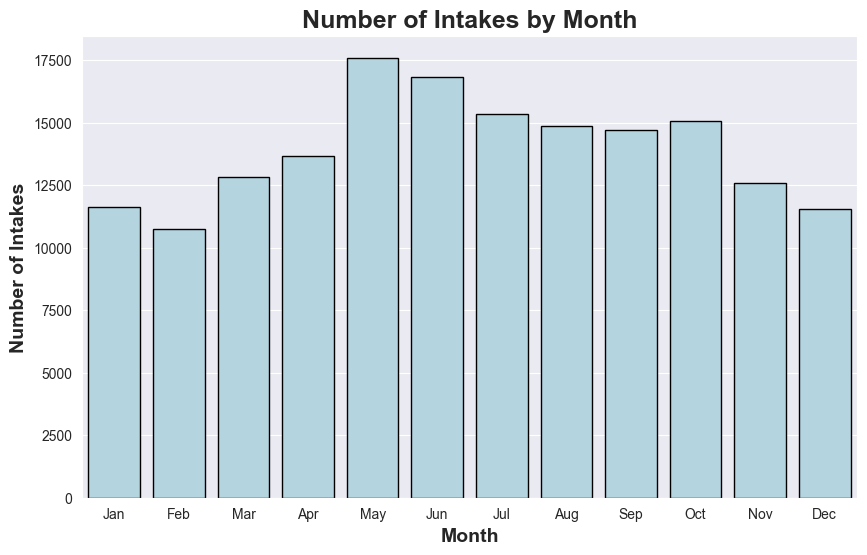

In [15]:
intakes_df['Intake Month'] = intakes_df['DateTime'].dt.month
month_counts = intakes_df['Intake Month'].value_counts().sort_index()

plt.figure(figsize=(10, 6))

sns.barplot(x=month_counts.index, y=month_counts.values, color='lightblue', edgecolor='black')
plt.title('Number of Intakes by Month', fontweight='bold', fontsize=18)
plt.xlabel('Month', fontweight='bold', fontsize=14)
plt.ylabel('Number of Intakes', fontweight='bold', fontsize=14)
plt.xticks(ticks=range(0, 12), labels=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
plt.xticks(rotation=0)
plt.show()

We can see that the most number of intakes were during May to October.

### Distribution by Day of the Week

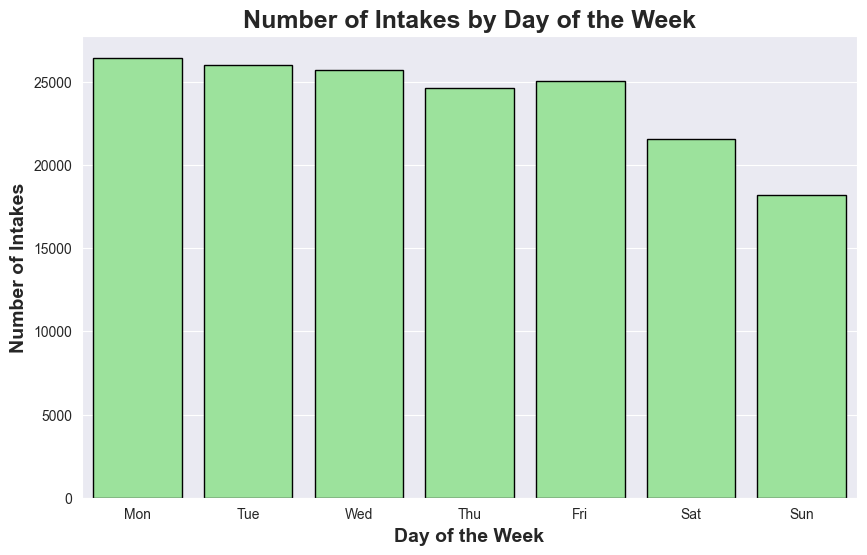

In [16]:
intakes_df['Intake Weekday'] = intakes_df['DateTime'].dt.weekday

plt.figure(figsize=(10, 6))
weekday_counts = intakes_df['Intake Weekday'].value_counts().sort_index()

sns.barplot(x=weekday_counts.index, y=weekday_counts.values, color='lightgreen', edgecolor='black')
plt.title('Number of Intakes by Day of the Week', fontweight='bold', fontsize=18)
plt.xlabel('Day of the Week', fontweight='bold', fontsize=14)
plt.ylabel('Number of Intakes', fontweight='bold', fontsize=14)
plt.xticks(ticks=range(7), labels=['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'])
plt.xticks(rotation=0)
plt.show()

We can see that number of intakes is almost the same everyday, instead of Sunday and Saturday, because these days are weekends.

## 3. Description of Intake Type, Animal Type, Sex upon Intake

### 1. Intake Type description

General description for **Intake Type**:

In [17]:
print('Descriptive statistics for Intake Type:')
intakes_df['Intake Type'].describe()

Descriptive statistics for Intake Type:


count     167524
unique         6
top        Stray
freq      114915
Name: Intake Type, dtype: object

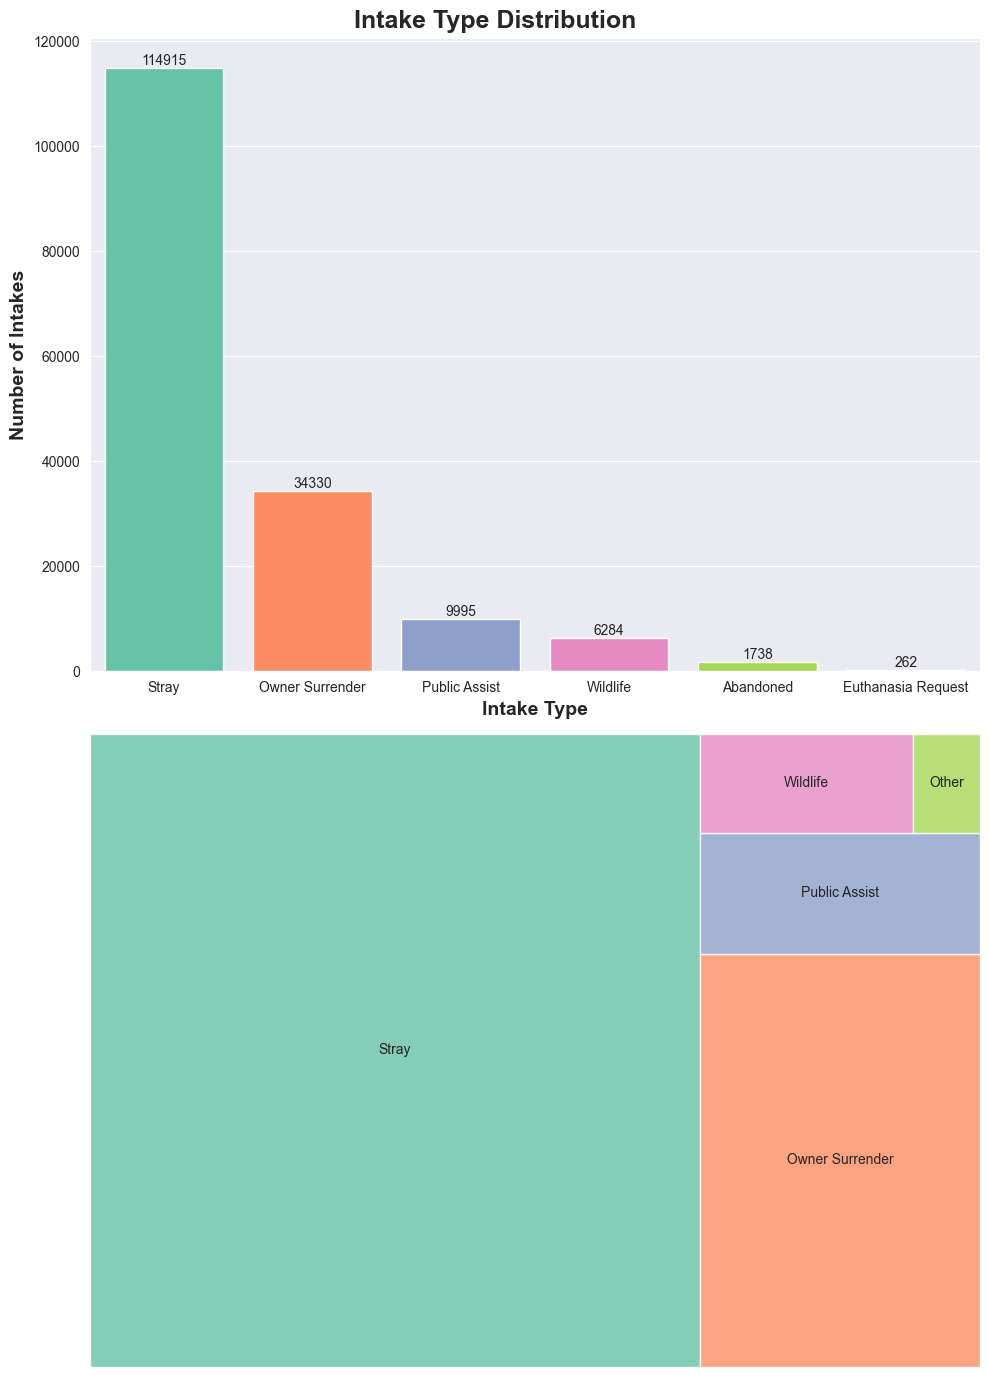

In [18]:
def columnTreeMap(df, column, xlabel, ylabel, suptitle):
    freq_counts = df[column].value_counts()

    large_categories = freq_counts[freq_counts / freq_counts.sum() >= 0.03].copy()
    small_categories = freq_counts[freq_counts / freq_counts.sum() < 0.03]

    if len(small_categories) > 0:
        large_categories.loc['Other'] = small_categories.sum()

    unique_values = df[column].value_counts().index
    colors = sns.color_palette("Set2", len(unique_values))
    
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10,14))
    
    sns.countplot(data=df, x=column, order=unique_values, ax=ax1)

    for i, bar in enumerate(ax1.patches):
        bar.set_facecolor(colors[i])
    
    ax1.bar_label(ax1.containers[0])

    ax1.set_xlabel(xlabel, fontweight='bold', fontsize=14)

    ax1.set_ylabel(ylabel, fontweight='bold', fontsize=14)
    
    squarify.plot(sizes=large_categories, label=large_categories.index, alpha=.8, color=colors, ax=ax2)
    ax2.axis('off')

    plt.suptitle(suptitle, fontsize=18, fontweight='bold')
    plt.tight_layout()
    plt.show()

columnTreeMap(intakes_df, 'Intake Type', 'Intake Type', 'Number of Intakes','Intake Type Distribution')

We can see that most of the animals were brought to the shelter as **Stray** and, conversely, the least number of animals were brought to the shelter as **Euthanasia Request**.

### 2. Animal Type description

General description for **Animal Type**:

In [19]:
print('Descriptive statistics for Animal Type:')
intakes_df['Animal Type'].describe()

Descriptive statistics for Animal Type:


count     167524
unique         5
top          Dog
freq       91631
Name: Animal Type, dtype: object

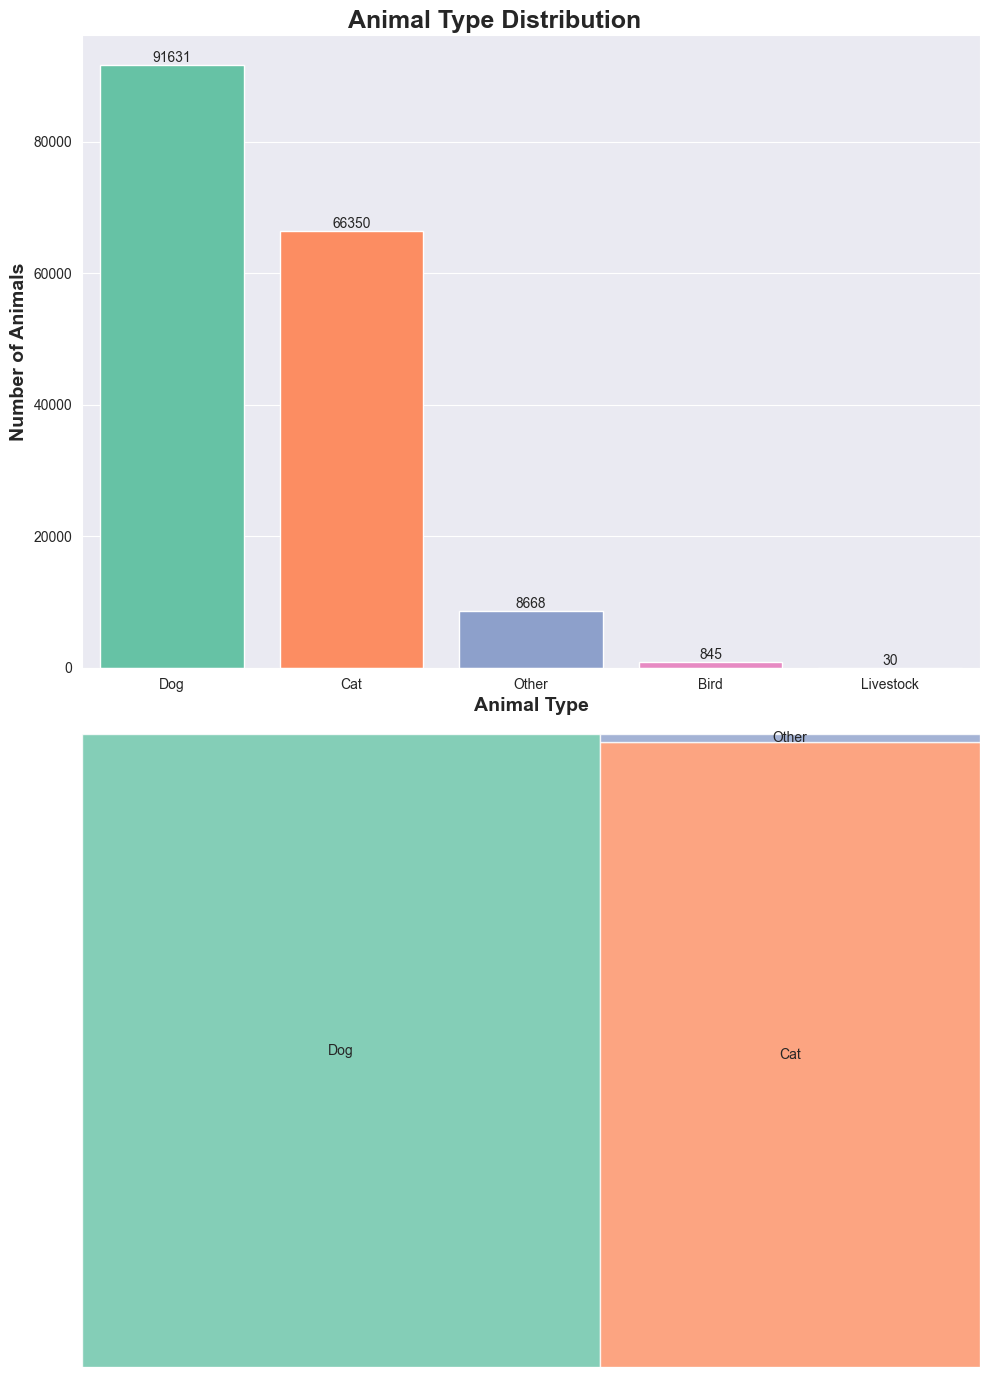

In [20]:
columnTreeMap(intakes_df, 'Animal Type', 'Animal Type', 'Number of Animals', 'Animal Type Distribution')

We can see that most of the animals in the shelter are **Dogs** and **Cats** and the least number of animals are **Birds** and **Livestock**.


### 3. Sex upon Intake description

General description for **Sex upon Intake**:

In [21]:
print('Descriptive statistics for Sex upon Intake:')
intakes_df['Sex upon Intake'].describe()

Descriptive statistics for Sex upon Intake:


count          154490
unique              4
top       Intact Male
freq            56720
Name: Sex upon Intake, dtype: object

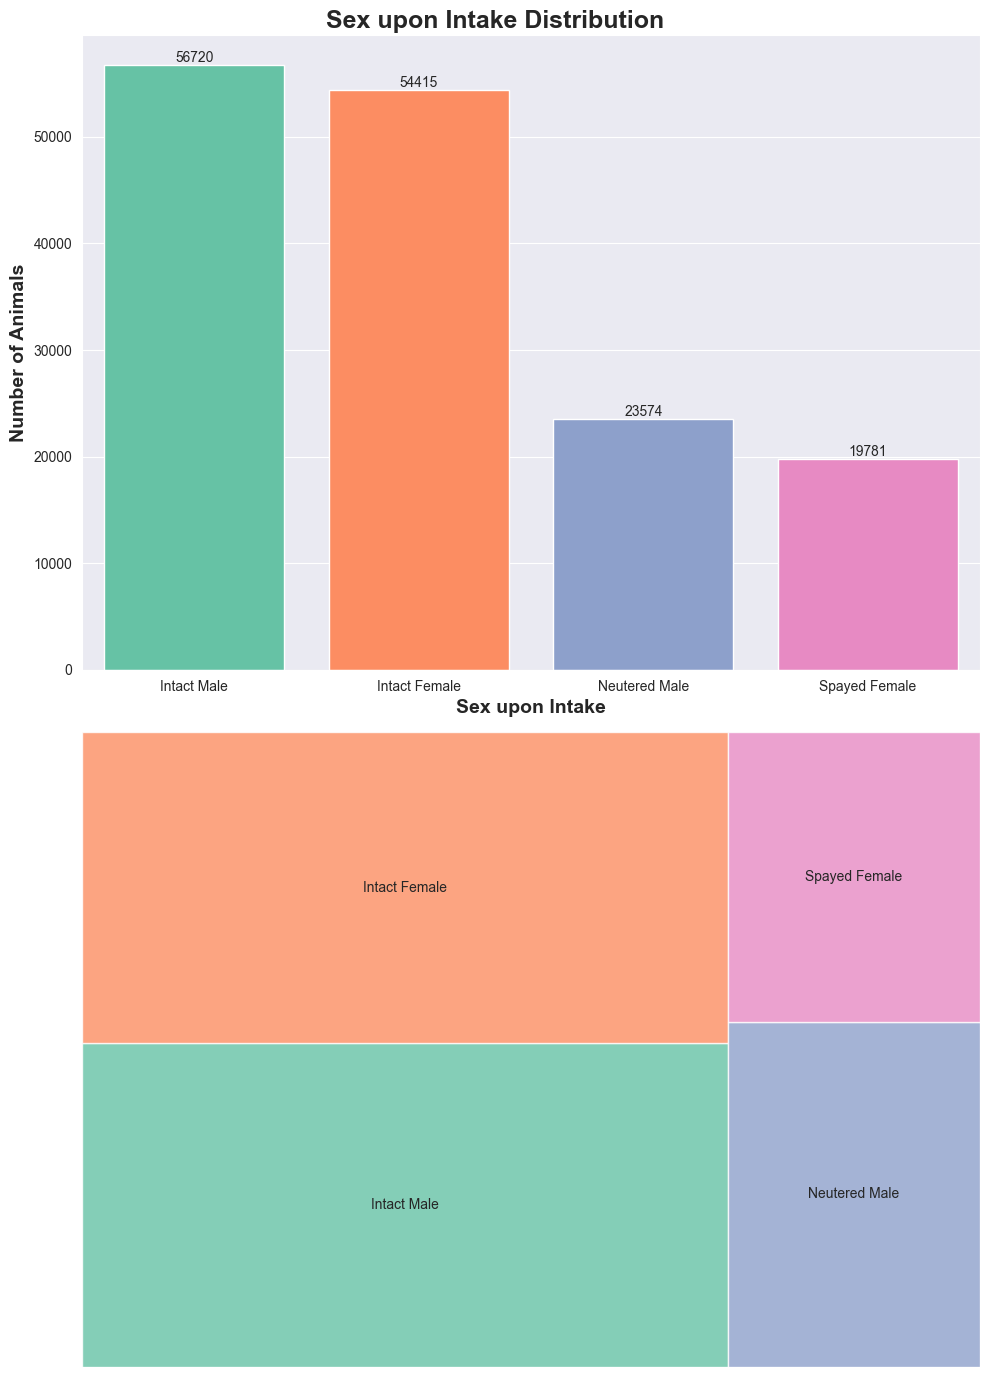

In [22]:
columnTreeMap(intakes_df, 'Sex upon Intake', 'Sex upon Intake', 'Number of Animals', 'Sex upon Intake Distribution')

**Intact Male** and **Intact Female** were the most frequently accepted animals into the shelter, while **Neutered Male** and **Spayed Female** were the least accepted

## 🤝 Relationship between **Sex upon Intake** and **Sex upon Outcome**

Using bivariate descriptive statistics, we examine the relationship between two categories

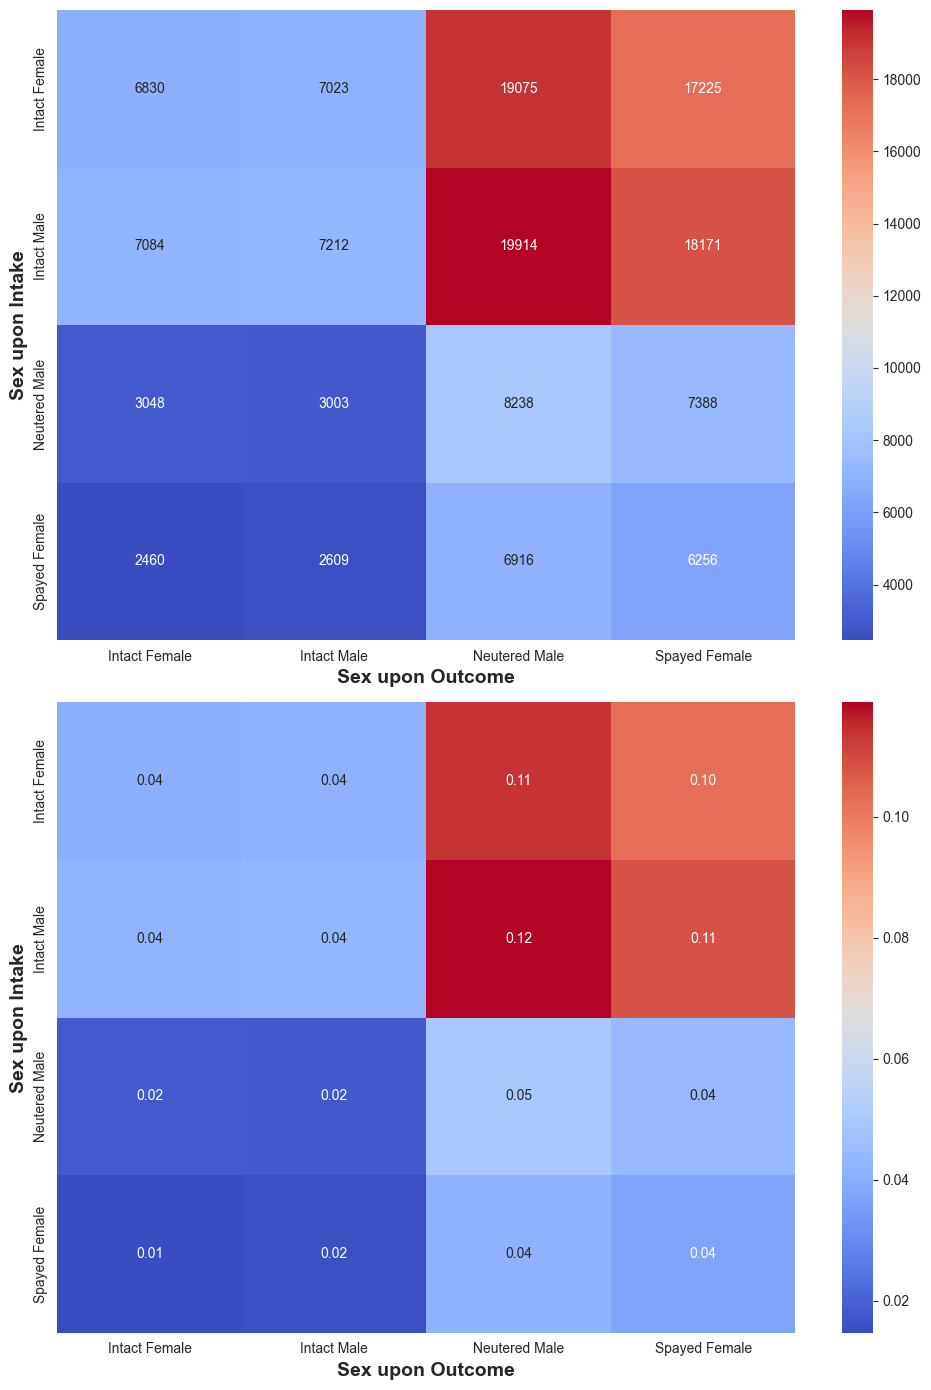

In [23]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 14))

frequency_table = pd.crosstab(intakes_df['Sex upon Intake'], outcomes_df['Sex upon Outcome'])
sns.heatmap(frequency_table, cmap='coolwarm', annot=True, fmt='g', ax=ax1)
ax1.set_xlabel('Sex upon Outcome', fontweight='bold', fontsize=14)
ax1.set_ylabel('Sex upon Intake', fontweight='bold', fontsize=14)

sns.heatmap(frequency_table.div(len(intakes_df)), cmap='coolwarm', annot=True, fmt='.2f', ax=ax2)
ax2.set_xlabel('Sex upon Outcome', fontweight='bold', fontsize=14)
ax2.set_ylabel('Sex upon Intake', fontweight='bold', fontsize=14)
plt.tight_layout()
plt.show()


The heatmaps show the relationship between "Sex upon Intake" and "Sex upon Outcome". We can see, that most animals are neutered after entering the shelter.

# **3. Questions**

### 🤔 Does the Outcome Type depend on the Intake Type?

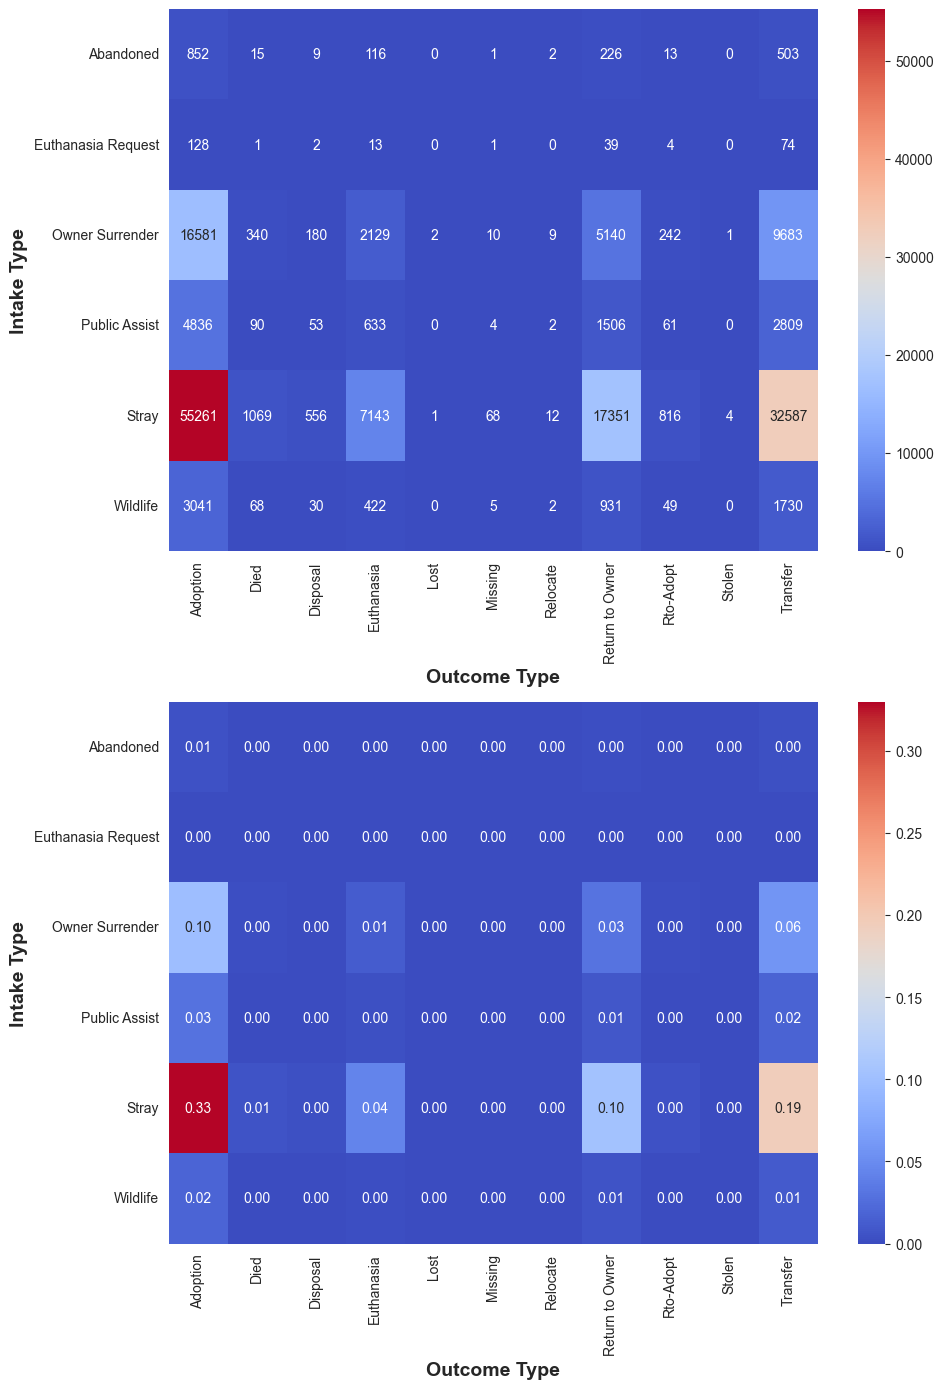

In [24]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 14))

sns.heatmap(pd.crosstab(intakes_df['Intake Type'], outcomes_df['Outcome Type']), cmap='coolwarm', annot=True, fmt='g', ax=ax1)
ax1.set_xlabel('Outcome Type', fontweight='bold', fontsize=14)
ax1.set_ylabel('Intake Type', fontweight='bold', fontsize=14)

sns.heatmap((pd.crosstab(intakes_df['Intake Type'], outcomes_df['Outcome Type'])).div(len(intakes_df)), cmap='coolwarm', annot=True, fmt='.2f', ax=ax2)
ax2.set_xlabel('Outcome Type', fontweight='bold', fontsize=14)
ax2.set_ylabel('Intake Type', fontweight='bold', fontsize=14)
plt.tight_layout()
plt.show()


👍 Yes, the Outcome Type depends on the Intake Type. The most common Outcome Type for animals brought to the shelter as **Stray** and **Owner Surrender** is **Adoption**. It's also very common for **Stray** and **Owner Surrender** to be **Transfer**.

### 🤔 Does the age of the animal play a role in adoption?

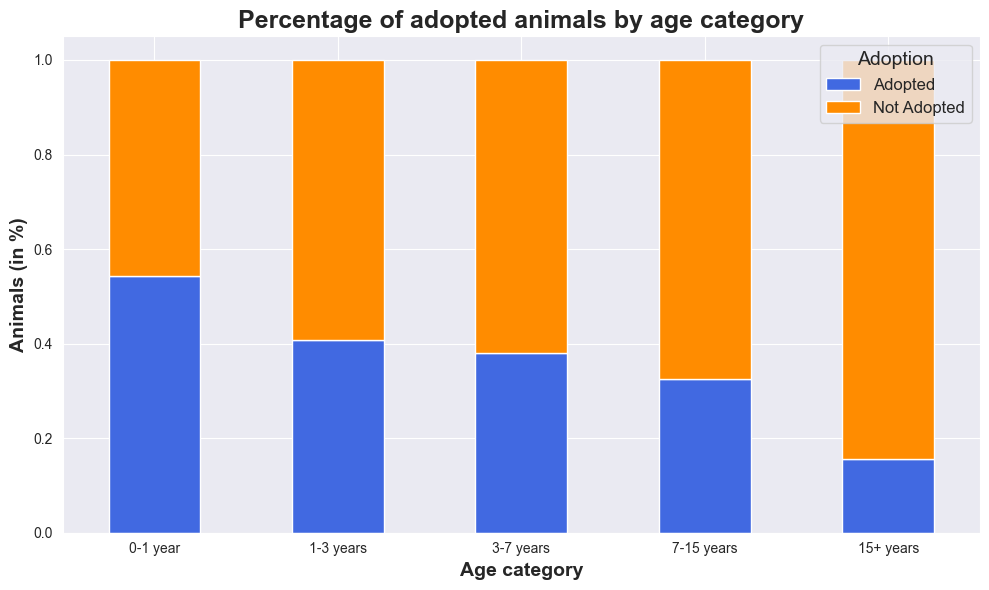

In [25]:
bins = [0, 1, 3, 7, 15, 100]
labels = ['0-1 year', '1-3 years', '3-7 years', '7-15 years', '15+ years']

outcomes_df['Age Category'] = pd.cut(outcomes_df['Age upon Outcome'], bins=bins, labels=labels)
outcomes_df['Adopted'] = outcomes_df['Outcome Type'].apply(lambda x: 'Adopted' if x == 'Adoption' else 'Not Adopted')

age_adoption_ct = pd.crosstab(outcomes_df['Age Category'], outcomes_df['Adopted'], normalize='index')

age_adoption_ct.plot(kind='bar', stacked=True, color=['royalblue', 'darkorange'], figsize=(10, 6))

plt.title('Percentage of adopted animals by age category', fontweight='bold', fontsize=18)
plt.xlabel('Age category', fontweight='bold', fontsize=14)
plt.ylabel('Animals (in %)', fontweight='bold', fontsize=14)
plt.legend(title='Adoption', title_fontsize='14', fontsize='12')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

👍 Yes, the age of the animal plays a role in adoption, and from the chart above we can see that young animals are the most commonly adopted. And conversely, older animals are the least likely to be adopted 🥺

### 🤔 Is the intake of animals constant throughout the year or are there periods with higher/lower loads?

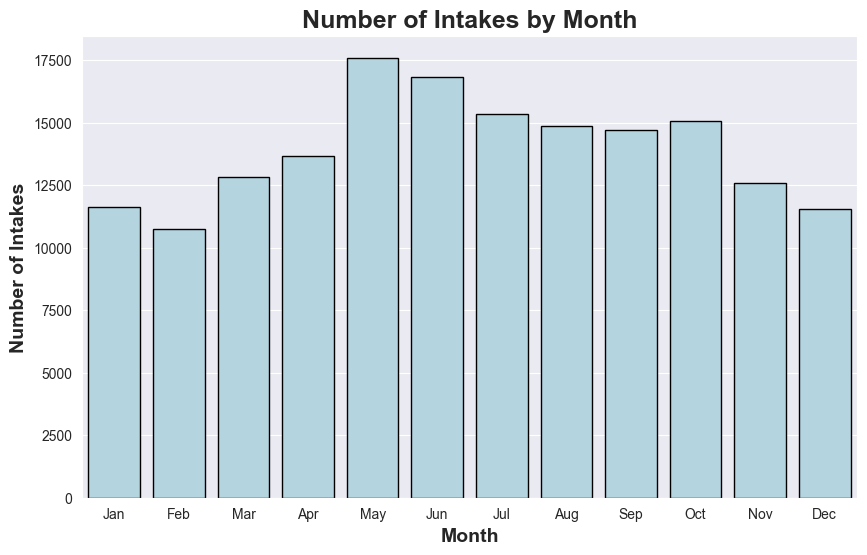

In [26]:
intakes_df['Intake Month'] = intakes_df['DateTime'].dt.month
month_counts = intakes_df['Intake Month'].value_counts().sort_index()

plt.figure(figsize=(10, 6))

sns.barplot(x=month_counts.index, y=month_counts.values, color='lightblue', edgecolor='black')
plt.title('Number of Intakes by Month', fontweight='bold', fontsize=18)
plt.xlabel('Month', fontweight='bold', fontsize=14)
plt.ylabel('Number of Intakes', fontweight='bold', fontsize=14)
plt.xticks(ticks=range(0, 12), labels=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
plt.xticks(rotation=0)
plt.show()

In previous tasks we have already mentioned this graph. On it we can see how the intake of animals to the shelter changes during the year. For example, most animals are intaken from May to October. Conversely, from November to April, fewer animals are intaken.

# 4. **My questions 💭**

For this, we need to read the data from the locations.csv file

In [27]:
locations_df = pd.read_csv('locations.csv')

✅ Data was successfully read and now using command **info()** we can see general information about data in these files: 

In [28]:
locations_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 109 entries, 0 to 108
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Animal ID       109 non-null    object
 1   Found Location  109 non-null    object
 2   At AAC          109 non-null    object
 3   Intake Date     109 non-null    object
 4   Type            109 non-null    object
 5   Looks Like      109 non-null    object
 6   Color           109 non-null    object
 7   Sex             109 non-null    object
 8   Age             109 non-null    object
 9   Image Link      109 non-null    object
dtypes: object(10)
memory usage: 8.6+ KB


Using command **shape** to show an info about count of rows and columns in dataset;\
Using command **display()** we will see the first and the last 5 rows of data in our dataset:

In [29]:
print(f'\nNumber of rows and columns in intakes dataset: {locations_df.shape}')

display(locations_df)


Number of rows and columns in intakes dataset: (109, 10)


,Animal ID,Found Location,At AAC,Intake Date,Type,Looks Like,Color,Sex,Age,Image Link
0,A768798,"4021 STECK AVENUE\nAUSTIN 78759\n(30.37351, -9...",Yes (come to the shelter),09/25/2024,Cat,Domestic Medium Hair Mix,Tortie,Spayed Female,14 years,http://www.petharbor.com/pet.asp?uaid=ASTN.A76...
1,A913908,"2606 WHELESS LN\nAUSTIN 78723\n(30.31094, -97....",Yes (come to the shelter),09/23/2024,Cat,Domestic Shorthair,Brown Tabby,Intact Male,2 weeks,http://www.petharbor.com/pet.asp?uaid=ASTN.A91...
2,A913909,"2606 WHELESS LN\nAUSTIN 78723\n(30.31094, -97....",Yes (come to the shelter),09/23/2024,Cat,Domestic Shorthair,Brown Tabby,Intact Female,2 weeks,http://www.petharbor.com/pet.asp?uaid=ASTN.A91...
3,A914098,5107 S IH\nAUSTIN 78744,Yes (come to the shelter),09/26/2024,Dog,Labrador Retriever Mix,Brown Brindle/White,Intact Male,6 months,http://www.petharbor.com/pet.asp?uaid=ASTN.A91...
4,A913910,"2606 WHELESS LN\nAUSTIN 78723\n(30.31094, -97....",Yes (come to the shelter),09/23/2024,Cat,Domestic Shorthair,Black,Intact Male,2 weeks,http://www.petharbor.com/pet.asp?uaid=ASTN.A91...
...,...,...,...,...,...,...,...,...,...,...
104,A913938,"5408 ATASCOSA DR\nAUSTIN 78758\n(30.19193, -97...",Yes (come to the shelter),09/23/2024,Cat,Domestic Shorthair,Brown Tabby/White,Intact Male,3 weeks,http://www.petharbor.com/pet.asp?uaid=ASTN.A91...
105,A913922,12101 SALEM HOUSE WAY\nAUSTIN 78753\n(30.38836...,Yes (come to the shelter),09/23/2024,Cat,Domestic Medium Hair,Orange Tabby/White,Intact Female,2 years,http://www.petharbor.com/pet.asp?uaid=ASTN.A91...
106,A913924,12101 SALEM HOUSE WAY\nAUSTIN 78753\n(30.38836...,Yes (come to the shelter),09/23/2024,Cat,Domestic Medium Hair,Orange Tabby/White,Intact Male,3 weeks,http://www.petharbor.com/pet.asp?uaid=ASTN.A91...
107,A913925,12101 SALEM HOUSE WAY\nAUSTIN 78753\n(30.38836...,Yes (come to the shelter),09/23/2024,Cat,Domestic Medium Hair,Orange Tabby,Intact Male,3 weeks,http://www.petharbor.com/pet.asp?uaid=ASTN.A91...


Using command **nunique()** look at the type of data in each column and see how many unique values each column has.

In [30]:
locations_df.nunique()

Animal ID         109
Found Location     49
At AAC              2
Intake Date         7
Type                2
Looks Like         19
Color              33
Sex                 5
Age                21
Image Link        109
dtype: int64

#### Now let's perform the same steps to prepare the dataset, as we did with the previous datasets.

Replacing missing or ambiguous values:

In [31]:
locations_df.replace(['', 'Unknown', 'None'], np.nan, inplace=True)

Converting **Age** to float64 format:

In [32]:
locations_df['Age'] = locations_df['Age'].apply(age_to_days)
locations_df['Age'] = locations_df['Age'].astype('float64')

Converting to **Yes** and **No** format **At AAC** column:

In [33]:
def at_aac(element):
    if "Yes" in element:
        return "Yes"
    elif "No" in element:
        return "No"
    else:
        return element
    
locations_df['At AAC'] = locations_df['At AAC'].apply(at_aac)

🔁1. We are converting categorical columns to **category** datatype

🔁2. We are converting **Intake Date** column to a **dateTime** format

✅3. We are removing **duplicates** from datasets

In [34]:
locationsToCategory = ["At AAC", "Type", "Looks Like","Color","Sex"]

locations_df[locationsToCategory] = locations_df[locationsToCategory].astype('category')

locations_df['Intake Date'] = pd.to_datetime(locations_df['Intake Date'], format='%m/%d/%Y')

locations_df.drop_duplicates(inplace=True)

🚀 Now we're ready

In [35]:
display(locations_df)

,Animal ID,Found Location,At AAC,Intake Date,Type,Looks Like,Color,Sex,Age,Image Link
0,A768798,"4021 STECK AVENUE\nAUSTIN 78759\n(30.37351, -9...",Yes,2024-09-25,Cat,Domestic Medium Hair Mix,Tortie,Spayed Female,14.000000,http://www.petharbor.com/pet.asp?uaid=ASTN.A76...
1,A913908,"2606 WHELESS LN\nAUSTIN 78723\n(30.31094, -97....",Yes,2024-09-23,Cat,Domestic Shorthair,Brown Tabby,Intact Male,0.038462,http://www.petharbor.com/pet.asp?uaid=ASTN.A91...
2,A913909,"2606 WHELESS LN\nAUSTIN 78723\n(30.31094, -97....",Yes,2024-09-23,Cat,Domestic Shorthair,Brown Tabby,Intact Female,0.038462,http://www.petharbor.com/pet.asp?uaid=ASTN.A91...
3,A914098,5107 S IH\nAUSTIN 78744,Yes,2024-09-26,Dog,Labrador Retriever Mix,Brown Brindle/White,Intact Male,0.500000,http://www.petharbor.com/pet.asp?uaid=ASTN.A91...
4,A913910,"2606 WHELESS LN\nAUSTIN 78723\n(30.31094, -97....",Yes,2024-09-23,Cat,Domestic Shorthair,Black,Intact Male,0.038462,http://www.petharbor.com/pet.asp?uaid=ASTN.A91...
...,...,...,...,...,...,...,...,...,...,...
104,A913938,"5408 ATASCOSA DR\nAUSTIN 78758\n(30.19193, -97...",Yes,2024-09-23,Cat,Domestic Shorthair,Brown Tabby/White,Intact Male,0.057692,http://www.petharbor.com/pet.asp?uaid=ASTN.A91...
105,A913922,12101 SALEM HOUSE WAY\nAUSTIN 78753\n(30.38836...,Yes,2024-09-23,Cat,Domestic Medium Hair,Orange Tabby/White,Intact Female,2.000000,http://www.petharbor.com/pet.asp?uaid=ASTN.A91...
106,A913924,12101 SALEM HOUSE WAY\nAUSTIN 78753\n(30.38836...,Yes,2024-09-23,Cat,Domestic Medium Hair,Orange Tabby/White,Intact Male,0.057692,http://www.petharbor.com/pet.asp?uaid=ASTN.A91...
107,A913925,12101 SALEM HOUSE WAY\nAUSTIN 78753\n(30.38836...,Yes,2024-09-23,Cat,Domestic Medium Hair,Orange Tabby,Intact Male,0.057692,http://www.petharbor.com/pet.asp?uaid=ASTN.A91...


### 🤔 What is the distribution of animals?

In [36]:
print('Descriptive statistics for Type:')
locations_df['Type'].describe()

Descriptive statistics for Type:


count     109
unique      2
top       Cat
freq       88
Name: Type, dtype: object

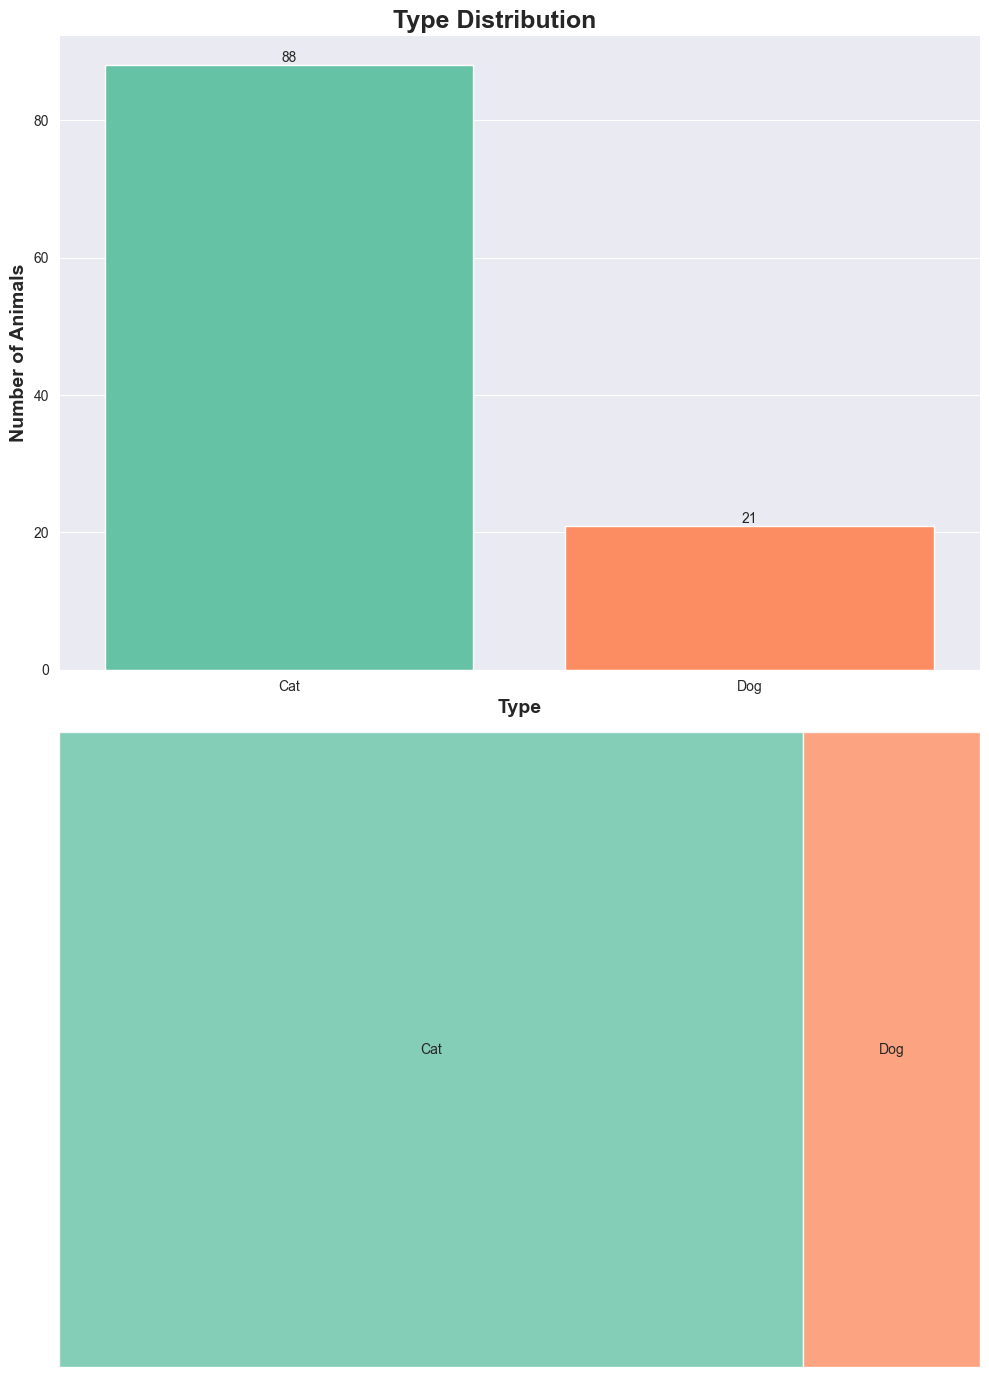

In [37]:
columnTreeMap(locations_df, 'Type', 'Type', 'Number of Animals', 'Type Distribution')

🐱 We can see that most of the animals are cats. There's a lot less dogs.

### 🤔 How many animals are in the shelter and how many are with volunteers?

In [38]:
print('Descriptive statistics for At AAC:')
locations_df['At AAC'].describe()

Descriptive statistics for At AAC:


count     109
unique      2
top       Yes
freq       94
Name: At AAC, dtype: object

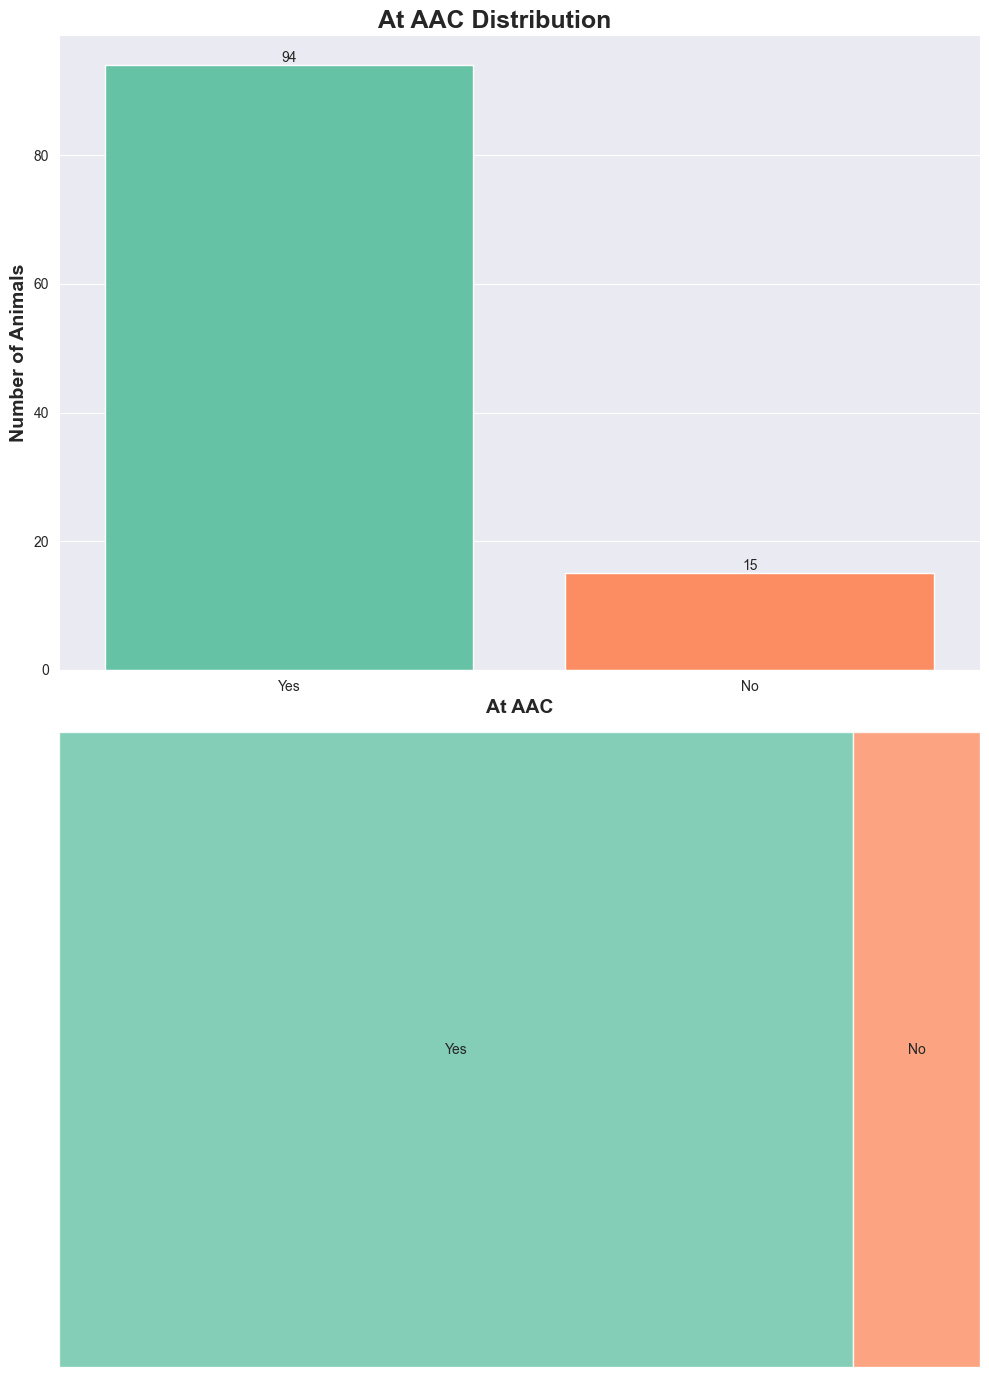

In [39]:
columnTreeMap(locations_df, 'At AAC', 'At AAC', 'Number of Animals', 'At AAC Distribution')

We can see that most of the animals are in the shelter, and only a small part is with volunteers 🦺

### 🤔 What is the distribution of animals by color?

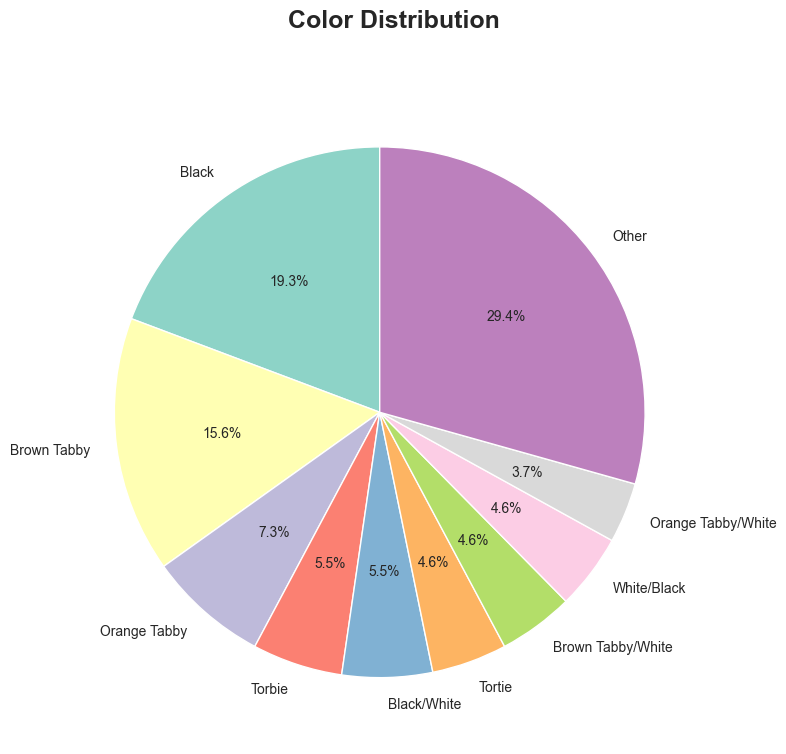

In [40]:
freq_counts = locations_df['Color'].value_counts()

large_categories = freq_counts[freq_counts / freq_counts.sum() >= 0.03].copy()
small_categories = freq_counts[freq_counts / freq_counts.sum() < 0.03]

if len(small_categories) > 0:
    large_categories.loc['Other'] = small_categories.sum()

fig, ax = plt.subplots(1, 1, figsize=(8, 8))
ax.pie(large_categories, labels=large_categories.index, autopct='%1.1f%%', startangle=90)
plt.suptitle('Color Distribution', fontsize=18, fontweight='bold')
plt.tight_layout()
plt.show()


We can see that most of the animals are **Black** and **Brown Tabby**. Nevertheless there are a lot of different colors of animals.

# (☞ ͡° ͜ʖ ͡°)☞ The End 